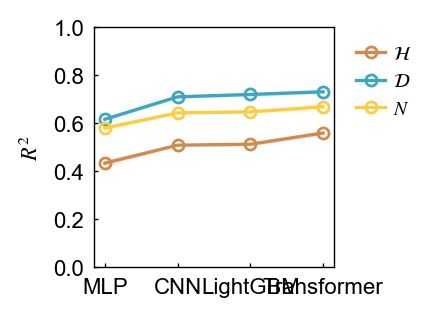

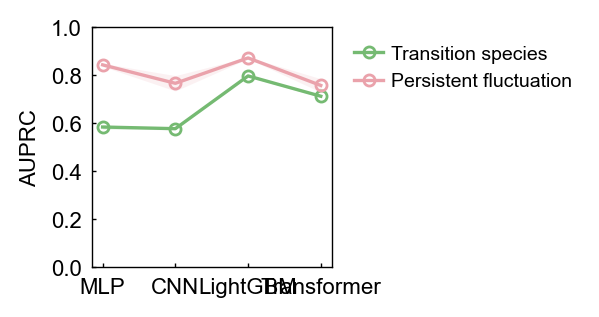

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load data
df = pd.read_excel("Multimodels_Compare.xlsx", index_col=0)

# Set publication-style parameters
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 8,
    'axes.labelsize': 8,
    'axes.titlesize': 9,
    'axes.linewidth': 0.5,
    'legend.fontsize': 7,
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'xtick.major.size': 1.5,
    'ytick.major.size': 1.5,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'mathtext.fontset': 'stix',
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})

# Model order
model_order = ["MLP", "CNN", "LightGBM", "Transformer"]

# Define prediction tasks and corresponding colors
r2_tasks = {
    "H_R2": (r"$\mathcal{H}$", "#cf8c51"),
    "D_R2": (r"$\mathcal{D}$", "#40a6bd"),
    "N_R2": (r"$N$", "#f8ce45")
}

auprc_tasks = {
    "trans_AUPRC": ("Transition species", "#75ba72"),
    "fluc_AUPRC": ("Persistent fluctuation", "#eaa2ab")
}


def plot_model_comparison(df, tasks, ylabel, filename, figsize=(2.2, 1.8), ylim=(0, 1)):

    fig, ax = plt.subplots(figsize=figsize, dpi=200)

    x = np.arange(len(model_order))

    for task, (label, color) in tasks.items():

        # Extract three repetitions
        columns = [f"{task}_r{i}" for i in range(1, 4)]

        values = df.set_index(df.index)[columns].loc[model_order]

        # Calculate mean and sample standard deviation
        mean = values.mean(axis=1).values
        std = values.std(axis=1, ddof=1).values

        # Plot mean performance
        ax.plot(
            x,
            mean,
            color=color,
            marker='o',
            markersize=4,
            markerfacecolor='none',
            markeredgewidth=1,
            linewidth=1.2,
            label=label,
            zorder=3
        )

        # Plot mean ± SD
        poly = ax.fill_between(
            x,
            mean - std,
            mean + std,
            color=color,
            alpha=0.15,
            linewidth=0,
            zorder=1
        )

        poly.set_rasterized(True)
        # # Annotate mean ± SD
        # for j in range(len(model_order)):
        #     ax.annotate(
        #         f"{mean[j]:.2f} ± {std[j]:.2f}",
        #         xy=(x[j], mean[j]),
        #         xytext=(0, 7),
        #         textcoords="offset points",
        #         ha="center",
        #         va="bottom",
        #         fontsize=5.5,
        #         color=color
        #     )
    # Axis settings
    ax.set_xticks(x)
    ax.set_xticklabels(model_order)
    ax.set_ylabel(ylabel)
    ax.set_ylim(ylim)

    ax.tick_params(direction='in')
    ax.grid(False)

    # Legend
    ax.legend(
        frameon=False,
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
        handlelength=1.5,
        handletextpad=0.4
    )


    plt.subplots_adjust(
        left=0.18,
        right=0.98,
        bottom=0.18,
        top=0.98
    )

    plt.savefig(
        filename,
        dpi=1000,
        bbox_inches='tight',
        transparent=True
    )

    plt.show()


# Figure 1: R2 prediction tasks
plot_model_comparison(
    df,
    tasks=r2_tasks,
    ylabel=r"$R^2$",
    filename="Model_Comparison_R2.pdf",
    figsize=(1.5, 1.5),
    ylim=(0, 1)
)

# Figure 2: AUPRC prediction tasks
plot_model_comparison(
    df,
    tasks=auprc_tasks,
    ylabel="AUPRC",
    filename="Model_Comparison_AUPRC.pdf",
    figsize=(1.5, 1.5),
    ylim=(0, 1)
)
